# 06 — Paired comparison of the baselines

Notebook 05 ranked the models by mean RMSE, but the gaps (a few hundredths) are about as large as the fold-to-fold spread. This notebook asks the sharper question: **on the same rows, is model A reliably better than model B?**

### Method
1. Refit each model family's winning configuration from `results/best_configs.json` on every fold and keep the validation predictions (cached in `results/baseline_predictions.parquet` so the reservoir notebooks can reuse them).
2. **Per fold:** RMSE of each model and the paired difference against the naive baseline and against ridge. Count the folds each model wins.
3. **Country-cluster bootstrap:** resample *countries* (not rows) with replacement, keeping every month of a resampled country, and recompute the pooled RMSE difference 2,000 times. Months within a country are strongly correlated, so resampling rows would make the intervals far too narrow. The 95% interval is the 2.5th–97.5th percentile of the differences. If it excludes 0, the difference is unlikely to come from which countries happened to be in the sample.

A difference is **RMSE(A) − RMSE(B)**; negative means A is better.

**Caveat carried over from 05:** each model's configuration was selected on these same folds, which favours the tuned models slightly. The locked test set is the clean check.

`QUICK_TEST = True` runs horizon 1 on a quarter of the rows.

## Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".git").exists():
    if root == root.parent:
        raise FileNotFoundError("Open this notebook from inside the DACSS_ML_FP repo.")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.paths import ROOT
from src.features.build import FEATURES
from src.eval.splits import FOLDS, fold_masks
from src.eval.paired import cluster_bootstrap_rmse_diff
from src.models.common import HORIZONS as ALL_H, load_features, make_table, naive_pred

# ------------------------------------------------------------------ settings
QUICK_TEST = False
REFIT = False            # True = ignore the cached predictions and refit everything
N_BOOT = 2000
SEED = 42
HORIZONS = [1] if QUICK_TEST else ALL_H
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
CACHE = RESULTS / ("baseline_predictions_quicktest.parquet" if QUICK_TEST else "baseline_predictions.parquet")
pd.set_option("display.width", 160, "display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 1.8, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

MODELS = ["naive (best window)", "ridge", "random forest", "gradient boosting"]
print(f"QUICK_TEST={QUICK_TEST}  horizons={HORIZONS}  cache -> {CACHE.relative_to(ROOT)}")

QUICK_TEST=False  horizons=[1, 3, 6, 12]  cache -> results\baseline_predictions.parquet


## 1. Refit the winners and collect validation predictions
Each fold's model is trained only on rows whose target month is on or before the fold's `train_end`, exactly as in notebook 05. Random forest is the slow one (a few minutes per horizon).

In [2]:
best = json.loads((RESULTS / ("best_configs_quicktest.json" if QUICK_TEST else "best_configs.json")).read_text())
feat = load_features()

def build(name, params):
    if name == "ridge":
        return make_pipeline(StandardScaler(), Ridge()).set_params(**params)
    if name == "random forest":
        return RandomForestRegressor(n_jobs=-1, random_state=SEED).set_params(**params)
    return HistGradientBoostingRegressor(random_state=SEED).set_params(**params)

KEEP = ["gwno", "country", "month", "y", "kind", "at_risk", "event"]
if CACHE.exists() and not REFIT:
    PRED = pd.read_parquet(CACHE)
    print("loaded cached predictions:", len(PRED), "rows")
else:
    parts = []
    for h in HORIZONS:
        d = make_table(feat, h)
        if QUICK_TEST:
            d = d[np.random.default_rng(SEED).random(len(d)) < 0.25].reset_index(drop=True)
        X = d[FEATURES].to_numpy(float); y = d["y"].to_numpy(float)
        masks = [fold_masks(d, f) for f in FOLDS]
        cfg = best[str(h)]
        p_naive = naive_pred(feat, d, cfg["naive_window"])
        for f, (tr, va) in zip(FOLDS, masks):
            parts.append(d.loc[va, KEEP].assign(horizon=h, model="naive (best window)", fold=f.name, pred=p_naive[va.to_numpy()]))
            for name in MODELS[1:]:
                m = build(name, cfg[name]["params"]).fit(X[tr], y[tr])
                parts.append(d.loc[va, KEEP].assign(horizon=h, model=name, fold=f.name, pred=m.predict(X[va])))
        print(f"horizon {h}: refit done")
    PRED = pd.concat(parts, ignore_index=True)
    PRED.to_parquet(CACHE)
    print("saved", CACHE.relative_to(ROOT), len(PRED), "rows")

horizon 1: refit done
horizon 3: refit done
horizon 6: refit done
horizon 12: refit done
saved results\baseline_predictions.parquet 489752 rows


## 2. Per-fold RMSE and paired differences
If a model's advantage over naive appears in all five folds, that is stronger evidence than a better average built from one or two folds.

In [3]:
def fold_rmse(h):
    p = PRED[PRED["horizon"] == h]
    return (p.assign(se=(p["y"] - p["pred"]) ** 2)
             .groupby(["model", "fold"])["se"].mean().pow(0.5).unstack("fold").reindex(MODELS))

wins = []
for h in HORIZONS:
    t = fold_rmse(h)
    print(f"Horizon {h}: validation RMSE by fold")
    display(t.round(4))
    for ref in ["naive (best window)", "ridge"]:
        for m in MODELS:
            if m == ref: continue
            diff = t.loc[m] - t.loc[ref]
            wins.append({"horizon": h, "model": m, "vs": ref, "folds won": int((diff < 0).sum()),
                         "of": len(diff), "mean diff": diff.mean(), "worst fold diff": diff.max()})
wins = pd.DataFrame(wins)
display(wins.round(4))

Horizon 1: validation RMSE by fold


fold,fold 1,fold 2,fold 3,fold 4,fold 5
model,,,,,
naive (best window),0.5383,0.4928,0.5039,0.5682,0.5379
ridge,0.5051,0.4702,0.4898,0.5427,0.5087
random forest,0.5097,0.4656,0.5029,0.5439,0.5019
gradient boosting,0.5095,0.4705,0.5139,0.5414,0.5011


Horizon 3: validation RMSE by fold


fold,fold 1,fold 2,fold 3,fold 4,fold 5
model,,,,,
naive (best window),0.5947,0.5775,0.5778,0.6137,0.5824
ridge,0.5753,0.5464,0.5721,0.5915,0.5682
random forest,0.5797,0.5441,0.6045,0.5946,0.5687
gradient boosting,0.5872,0.5486,0.6078,0.5954,0.5733


Horizon 6: validation RMSE by fold


fold,fold 1,fold 2,fold 3,fold 4,fold 5
model,,,,,
naive (best window),0.6171,0.6298,0.6623,0.6480,0.6025
ridge,0.6239,0.6140,0.6476,0.6316,0.5911
random forest,0.6283,0.6118,0.6890,0.6419,0.5901
gradient boosting,0.6330,0.6132,0.6982,0.6348,0.5980


Horizon 12: validation RMSE by fold


fold,fold 1,fold 2,fold 3,fold 4,fold 5
model,,,,,
naive (best window),0.7043,0.6957,0.7650,0.7133,0.6681
ridge,0.6972,0.6720,0.7532,0.6874,0.6335
random forest,0.7185,0.6725,0.7960,0.6850,0.6342
gradient boosting,0.7197,0.6886,0.7911,0.7104,0.6404


,horizon,model,vs,folds won,of,mean diff,worst fold diff
0,1,ridge,naive (best window),5,5,-0.0249,-0.0141
1,1,random forest,naive (best window),5,5,-0.0234,-0.0009
2,1,gradient boosting,naive (best window),4,5,-0.0209,0.0100
3,1,naive (best window),ridge,0,5,0.0249,0.0332
4,1,random forest,ridge,2,5,0.0016,0.0132
5,1,gradient boosting,ridge,2,5,0.0040,0.0241
6,3,ridge,naive (best window),5,5,-0.0185,-0.0057
7,3,random forest,naive (best window),4,5,-0.0109,0.0267
8,3,gradient boosting,naive (best window),4,5,-0.0068,0.0300
9,3,naive (best window),ridge,0,5,0.0185,0.0311


## 3. Country-cluster bootstrap on the pooled difference

In [4]:
pairs = [(m, "naive (best window)") for m in MODELS[1:]] + [("random forest", "ridge"), ("gradient boosting", "ridge")]
rows = []
for h in HORIZONS:
    p = PRED[PRED["horizon"] == h]
    wide = p.pivot_table(index=["gwno", "month"], columns="model", values="pred")
    base = p[p["model"] == "ridge"].set_index(["gwno", "month"])[["y"]]
    wide = wide.join(base).reset_index()
    for a, b in pairs:
        r = cluster_bootstrap_rmse_diff(wide["y"], wide[a], wide[b], wide["gwno"], B=N_BOOT, seed=SEED)
        rows.append({"horizon": h, "A": a, "B": b, **r})
paired = pd.DataFrame(rows)
paired["significant"] = (paired["lo"] > 0) | (paired["hi"] < 0)
display(paired.round(4))
paired.round(5).to_csv(RESULTS / ("paired_baselines_quicktest.csv" if QUICK_TEST else "paired_baselines.csv"), index=False)

,horizon,A,B,diff,lo,hi,p_a_better,significant
0,1,ridge,naive (best window),-0.0250,-0.0340,-0.0153,1.0000,True
1,1,random forest,naive (best window),-0.0234,-0.0339,-0.0103,0.9995,True
2,1,gradient boosting,naive (best window),-0.0211,-0.0349,-0.0014,0.9830,True
3,1,random forest,ridge,0.0016,-0.0034,0.0081,0.3050,False
4,1,gradient boosting,ridge,0.0040,-0.0044,0.0178,0.3040,False
5,3,ridge,naive (best window),-0.0185,-0.0312,-0.0055,0.9985,True
6,3,random forest,naive (best window),-0.0107,-0.0307,0.0155,0.8135,False
7,3,gradient boosting,naive (best window),-0.0066,-0.0280,0.0209,0.7025,False
8,3,random forest,ridge,0.0078,-0.0045,0.0266,0.1830,False
9,3,gradient boosting,ridge,0.0119,-0.0028,0.0329,0.0815,False


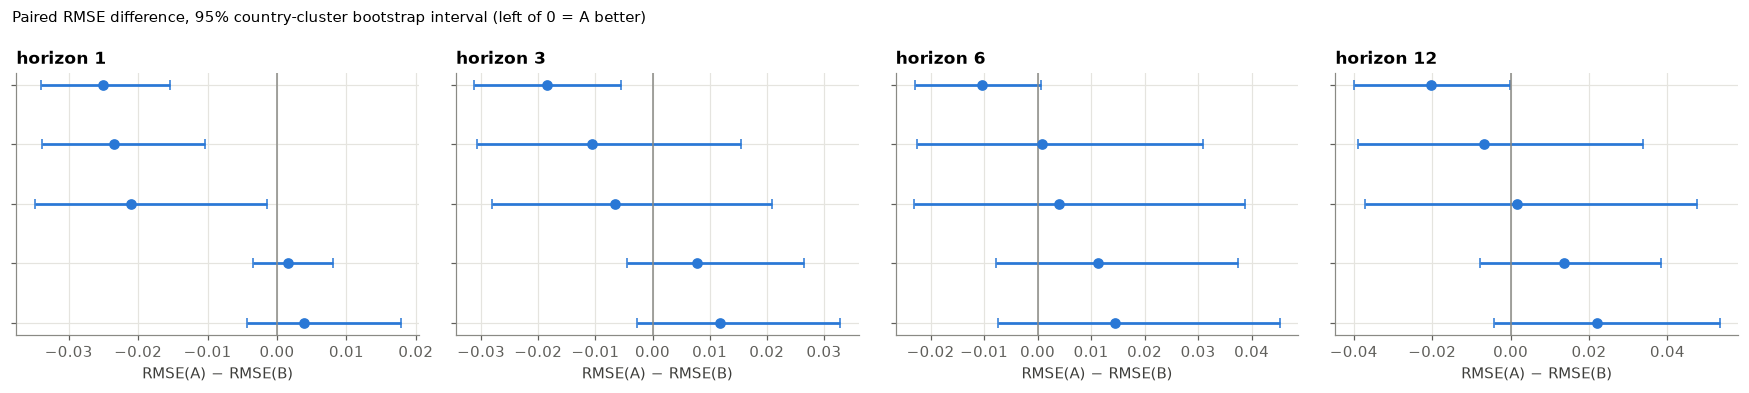

In [5]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(3.2 * len(HORIZONS) + 3.2, 3.6), sharey=True, squeeze=False)
labels = [f"{a} vs {b}" for a, b in pairs]
for ax, h in zip(axes[0], HORIZONS):
    s = paired[paired["horizon"] == h].reset_index(drop=True)
    y = np.arange(len(s))[::-1]
    ax.errorbar(s["diff"], y, xerr=[s["diff"] - s["lo"], s["hi"] - s["diff"]], fmt="o", color="#2a78d6", capsize=3)
    ax.axvline(0, color="#8a8a85", lw=1)
    ax.set_title(f"horizon {h}"); ax.set_xlabel("RMSE(A) − RMSE(B)")
    ax.set_yticks(y); ax.set_yticklabels(labels if ax is axes[0][0] else [], fontsize=8)
fig.suptitle("Paired RMSE difference, 95% country-cluster bootstrap interval (left of 0 = A better)", fontsize=10, x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 4. Reading the results
Fill in after the run. Check:
- Which model-vs-naive intervals exclude 0, and at which horizons?
- Does ridge beat random forest and gradient boosting, or are those differences inside the noise?
- Do the fold counts agree with the bootstrap? A model that wins four of five folds but has an interval spanning 0 is suggestive, not established.

These predictions are the reference the reservoir notebooks (07, 08) are compared against with the same bootstrap.